# Modelo Transformer: BERTimbau (busca) + mt0/T5 (geração)

Sistema que responde **perguntas de leigos sobre o Código Civil (Lei 10.406/2002)** em linguagem simples. É um **RAG** (geração aumentada por recuperação) de duas etapas:

```
pergunta ──► BERTimbau ──► 3 artigos mais parecidos ──► mt0 (T5) ──► resposta simples + artigo citado
            (vira vetor)   (só o TEXTO passa adiante)   (escreve)         ou recusa, se não houver base
```

- **BERTimbau** (`neuralmind/bert-base-portuguese-cased`) é o *bibliotecário*: transforma textos em vetores e acha os artigos mais próximos da pergunta. Não escreve nada.
- **mt0-base** (um T5 multilíngue) é o *redator*: recebe pergunta + artigos e escreve a resposta. Não busca nada.
- **A única ligação entre os dois é o texto dos artigos**, colado dentro do prompt do T5.

Os dois são **ajustados (fine-tuning) com perguntas de leigos** geradas para os 2.017 artigos vigentes, e avaliados em **treino, validação e teste**.

## Mapa do notebook
| Parte | O que faz |
|---|---|
| 1 | Configurações (caminhos, hiperparâmetros, perfil CPU/GPU) |
| 2–3 | Lê os artigos e o dataset de perguntas; confere que não há vazamento entre treino e teste |
| 4 | **Treina o BERTimbau** (perda de treino/validação + Recall@1 e MRR de validação por época) |
| 5 | ChromaDB: guarda os vetores e define a busca |
| 6 | **Desempenho da busca** em treino, validação, teste visto e teste novo (e comparação com o BERT original) |
| 7 | Calibra o **limiar de recusa** na validação |
| 8 | **Treina o mt0** (perda de treino/validação, acurácia de tokens por época) |
| 9 | **Desempenho do sistema completo** em treino, validação, teste visto e teste novo |
| 10 | Quadro-resumo salvo em `data/resultados/` e testes manuais |

> **Onde rodar.** O treino é pesado: **rode no Google Colab com GPU (T4)**, ~1 h no total. Só com CPU, o perfil `"rapido"` usa uma fração dos dados e serve para testar o código.

## Preparação do Ambiente (aJudAI)
O projeto aJudAI consome os artigos do Código Civil diretamente da coleção `artigos` do MongoDB (`rag_juridico`), através da classe `MongoConnection`, e os datasets de perguntas em `data/dataset/`.

Todos os modelos, checkpoints e resultados são salvos deterministicamente na estrutura de diretórios do projeto (`data/models/`, `data/chromadb_local/`, `data/resultados/`).


In [ ]:
# ---- Preparação de Ambiente: Colab ou Local ----
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "sentence-transformers", "datasets",
                    "accelerate", "chromadb", "transformers", "sentencepiece", "pymongo", "python-dotenv"], check=True)
    print("Colab: pacotes instalados.")
    import torch; print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NENHUMA - ative a GPU!")
else:
    print("Execução Local aJudAI (fora do Colab).")


Mounted at /content/drive
Colab: trabalhando em /content/drive/MyDrive/JudAI
GPU: Tesla T4


## Protocolo de avaliação (aJudAI)
- **Treino** (artigos de treino, perguntas de treino de `pares_bert_inicial.jsonl`).
- **Validação** (artigos separados para validação, perguntas de `pares_bert_inicial.jsonl`).
- **Teste visto** (artigos que estavam no treino, mas com **perguntas novas nunca vistas** de `avaliacao_inicial.jsonl`).
- **Teste novo** (artigos exclusivos que **nunca apareceram nem no treino nem na validação**).
- Zero sobreposição de artigos entre treino, validação e teste novo; zero sobreposição de perguntas entre treino e testes.


## 1. Configurações
Tudo o que você pode querer mudar fica neste bloco. O resto do notebook só usa essas variáveis.

- **`PERFIL`**: `"completo"` usa todos os dados (use com GPU); `"rapido"` usa poucos dados e poucas épocas (só para testar o código na CPU). `"auto"` escolhe pela presença de GPU.
- **`FORCAR_TREINO`**: por padrão cada modelo só é treinado se ainda **não existir** salvo em `models/`. Ponha `True` para treinar de novo.

In [ ]:
# ---------- Bibliotecas ----------
import json, math, random, re, sys, time   # leitura de arquivos, contas, aleatoriedade, texto, cronômetro
from pathlib import Path                   # caminhos de arquivo que funcionam no Windows, Linux e Colab

import numpy as np                         # contas com vetores
import torch                               # biblioteca de redes neurais (BERT e T5 rodam em cima dela)
import matplotlib.pyplot as plt            # gráficos

# ---------- Pasta do projeto aJudAI ----------
# Começa na pasta do notebook e sobe até achar a pasta raiz do projeto aJudAI (que contém data/dataset)
RAIZ = Path.cwd()
while not (RAIZ / "data" / "dataset").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

PASTA_DATASET    = RAIZ / "data" / "dataset"       # pares_bert_inicial.jsonl, avaliacao_inicial.jsonl
PASTA_RESULTADOS = RAIZ / "data" / "resultados"    # gráficos, históricos e quadros de resultados
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# ---------- Dispositivo e perfil ----------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PERFIL = "auto"                                    # "auto" | "completo" | "rapido"
if PERFIL == "auto":
    PERFIL = "completo" if DEVICE == "cuda" else "rapido"
FORCAR_TREINO = False                              # True: retreina mesmo que já exista modelo salvo
SEED = 42                                          # semente: torna sorteios e treino repetíveis

# ---------- BERT (busca) ----------
MODELO_BASE = "neuralmind/bert-base-portuguese-cased"   # BERTimbau original (Hugging Face)
SAIDA_BERT  = RAIZ / "data" / "models" / "bert_juridico"  # onde o BERT ajustado é salvo/carregado
LR_BERT     = 2e-5                                      # taxa de aprendizado (tamanho de cada ajuste)
if PERFIL == "completo":
    EPOCAS_BERT, BATCH_BERT, MAX_SEQ = 8, 32, 256       # passa 8x por todos os pares; 32 pares por passo; lê até 256 tokens
    N_PARES_BERT = None                                 # None = usa todos os pares de treino
    AVALIAR_BUSCA_POR_EPOCA = True                      # calcula Recall@1/MRR de validação a cada época (custa ~15 s na GPU)
    AVALIAR_ORIGINAL = True                             # também mede o BERTimbau original para comparar
else:
    EPOCAS_BERT, BATCH_BERT, MAX_SEQ = 3, 16, 128
    N_PARES_BERT = 600                                  # só 600 pares: serve para testar o código, não para obter qualidade
    AVALIAR_BUSCA_POR_EPOCA = False                     # na CPU, codificar os 2.017 artigos a cada época é lento demais
    AVALIAR_ORIGINAL = False

# ---------- ChromaDB (banco de vetores) ----------
CAMINHO_CHROMA = RAIZ / "data" / "chromadb_local"      # onde o ChromaDB guarda os vetores
PASTA_CKPT_BERT = RAIZ / "data" / "models" / "checkpoints_bert"  # checkpoints temporários do treino
NOME_COLECAO   = "cc_bert-juridico"                     # nome da coleção de vetores

# ---------- T5 / mt0 (geração) ----------
NOME_T5  = "bigscience/mt0-base"                        # mt0 original (T5 multilíngue)
SAIDA_T5 = RAIZ / "data" / "models" / "mt0_juridico"    # onde o mt0 ajustado é salvo/carregado
LR_T5    = 2e-4
K_CONTEXTO       = 3          # quantos artigos a busca entrega ao T5
MAX_CHARS_TRECHO = 900        # corta cada artigo nesse nº de caracteres dentro do prompt
MAX_ENTRADA      = 1024       # máximo de tokens do prompt (conferido na parte 8)
P_SEM_ARTIGO_CERTO = 0.10     # no treino, em 10% dos exemplos o artigo certo é REMOVIDO e o alvo vira "recusa" (simula falha da busca)
if PERFIL == "completo":
    EPOCAS_T5, BATCH_T5, ACUM_T5 = 5, 4, 4              # lotes de 4, acumulando 4 passos = lote efetivo de 16
    N_TREINO_T5, N_VAL_T5 = None, None                  # None = usa tudo
    N_AVAL_GER, BATCH_GERACAO = 150, 16                 # nº de perguntas por conjunto na avaliação final do sistema
else:
    EPOCAS_T5, BATCH_T5, ACUM_T5 = 2, 4, 1
    N_TREINO_T5, N_VAL_T5 = 80, 30
    N_AVAL_GER, BATCH_GERACAO = 12, 4

print("Projeto aJudAI:", RAIZ)
print("Dispositivo:", DEVICE, "| Perfil:", PERFIL)
if PERFIL == "rapido":
    print("ATENÇÃO: perfil rápido (CPU). Resultados servem só para validação do código; use GPU para treino completo.")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)


Projeto: /content/drive/MyDrive/JudAI
Dispositivo: cuda | Perfil: completo


## 2. Ler os artigos da lei
Cada artigo vigente vira uma **passagem**: um item da base com `id`, `citacao` (ex.: "Código Civil, art. 5º") e `texto`. Artigos revogados são ignorados.

In [ ]:
# Lê todos os artigos vigentes do Código Civil diretamente do MongoDB (coleção 'artigos')
from src.database.mongo_connection import MongoConnection

db = MongoConnection().get_db()
cursor_artigos = db["artigos"].find(
    {"vigente": True},
    {"_id": 1, "citacao": 1, "texto": 1, "texto_vigente": 1, "ordem": 1, "vigente": 1}
).sort("ordem", 1)

artigos = {}
passagens = []

for doc in cursor_artigos:
    artigo_id = doc["_id"]
    citacao = doc.get("citacao") or f"Código Civil, art. {doc.get('numero', '')}"
    texto = doc.get("texto_vigente") or doc.get("texto", "")
    # Remove prefixo 'Art. 5º ' redundante pois a citação já possui a identificação formal
    texto = re.sub(r"^Art\.\s*\S+\s+", "", texto).strip()
    
    artigos[artigo_id] = doc
    if texto:
        passagens.append({"id": artigo_id, "citacao": citacao, "texto": texto})

ids_passagens   = [p["id"] for p in passagens]                  # ids na mesma ordem das passagens
indice_de       = {i: n for n, i in enumerate(ids_passagens)}   # id -> posição na lista
passagem_por_id = {p["id"]: p for p in passagens}               # id -> passagem
# Texto que o modelo de busca lê: "citação. texto". Ex.: "Código Civil, art. 1º. Toda pessoa é capaz..."
textos_idx = [f"{p['citacao']}. {p['texto']}" for p in passagens]
print(f"{len(artigos)} artigos lidos do MongoDB | {len(passagens)} passagens vigentes indexáveis")


2083 artigos lidos | 2017 passagens vigentes


## 3. Ler o dataset de perguntas
Os arquivos `.jsonl` têm **um JSON por linha**. Depois de ler, o código **confere que nenhum artigo (nem pergunta) de validação ou de teste aparece no treino**: se isso falhasse, a nota de teste seria inflada.

In [ ]:
# Frase padrão de recusa
ABST = "Não encontrei informação suficiente no Código Civil para responder a essa pergunta."

def ler_jsonl(caminho):
    """Lê um arquivo .jsonl e devolve a lista de dicionários (um por linha)."""
    with open(caminho, encoding="utf-8") as f:
        return [json.loads(linha) for linha in f if linha.strip()]

def so_validas(linhas):
    """Descarta linhas cujo artigo não está nas passagens vigentes."""
    boas = [l for l in linhas if l.get("artigo_id") is None or l.get("artigo_id") in indice_de]
    if len(boas) != len(linhas):
        print(f"AVISO: {len(linhas) - len(boas)} linhas descartadas (artigo ausente/revogado)")
    return boas

# 1. Carrega os dois datasets versionados do aJudAI
pares_raw = so_validas(ler_jsonl(PASTA_DATASET / "pares_bert_inicial.jsonl"))
aval_raw  = so_validas(ler_jsonl(PASTA_DATASET / "avaliacao_inicial.jsonl"))

# 2. Particionamento Determinístico dos Artigos (Zero Leakage)
# pares_raw possui 24 artigos (3 perguntas cada = 72 pares).
# aval_raw possui 12 artigos (1 pergunta cada = 12 perguntas), todos contidos nos 24 artigos de pares_raw.
art_pares = sorted(list(set(l["artigo_id"] for l in pares_raw)))
art_aval  = sorted(list(set(l["artigo_id"] for l in aval_raw)))
art_exclusivos_pares = sorted(list(set(art_pares) - set(art_aval)))  # Exatamente 12 artigos

# Alocação dos artigos:
# - Treino: 12 artigos compartilhados + 4 artigos exclusivos = 16 artigos (48 pares de treino)
# - Validação: 4 artigos exclusivos = 4 artigos (12 pares de validação)
# - Teste Novo: 4 artigos exclusivos = 4 artigos (12 pares de teste com artigos nunca vistos no treino)
art_treino = set(art_aval + art_exclusivos_pares[:4])
art_val    = set(art_exclusivos_pares[4:8])
art_novo   = set(art_exclusivos_pares[8:12])

# Conjuntos de Busca
busca_treino      = [l for l in pares_raw if l["artigo_id"] in art_treino]
busca_val         = [l for l in pares_raw if l["artigo_id"] in art_val]
busca_teste_novo  = [l for l in pares_raw if l["artigo_id"] in art_novo]
# Teste Visto: 100% das 12 perguntas de aval_raw (artigos conhecidos pelo treino, perguntas nunca vistas)
busca_teste_visto = [l for l in aval_raw if l["artigo_id"] in art_treino]

# 3. Perguntas Fora do Escopo (artigo_id = None) para Calibração de Abstenção e Limiar
perguntas_fora_escopo = [
    "Qual é a capital da França?",
    "Como fazer um bolo de cenoura com cobertura de chocolate?",
    "Qual é a distância média entre a Terra e a Lua?",
    "Quem venceu a Copa do Mundo de futebol masculino de 2022?",
    "Como funciona a velocidade de escape de um foguete espacial?",
    "Posso roubar um carro se estiver com pressa?",
    "Qual é a pena prevista no Código Penal para estelionato?",
    "Quem escreveu a peça Romeu e Julieta?",
    "Como tratar uma dor de garganta em casa com remédio caseiro?",
    "Qual é a velocidade máxima permitida na rodovia Castello Branco?",
    "Quantos planetas existem no sistema solar?",
    "Como configurar uma rede Wi-Fi residencial segura?"
]
fora_treino = [{"pergunta": p, "artigo_id": None, "resposta": ABST} for p in perguntas_fora_escopo[:6]]
fora_val    = [{"pergunta": p, "artigo_id": None, "resposta": ABST} for p in perguntas_fora_escopo[6:9]]
fora_teste  = [{"pergunta": p, "artigo_id": None, "resposta": ABST} for p in perguntas_fora_escopo[9:]]

# 4. Geração de Respostas de Referência para o Gerador mT0
def criar_resposta_referencia(artigo_id):
    if artigo_id is None or artigo_id not in passagem_por_id:
        return ABST
    p = passagem_por_id[artigo_id]
    return f"{p['texto']} ({p['citacao']})"

gerador_treino = [{"pergunta": l["pergunta"], "artigo_id": l["artigo_id"], "resposta": criar_resposta_referencia(l["artigo_id"])}
                  for l in busca_treino] + fora_treino
gerador_val    = [{"pergunta": l["pergunta"], "artigo_id": l["artigo_id"], "resposta": criar_resposta_referencia(l["artigo_id"])}
                  for l in busca_val] + fora_val
gerador_teste  = [{"pergunta": l["pergunta"], "artigo_id": l["artigo_id"], "resposta": criar_resposta_referencia(l["artigo_id"])}
                  for l in busca_teste_novo] + fora_teste

resp_do_artigo = {l["artigo_id"]: l["resposta"] for l in gerador_treino if l["artigo_id"]}
gerador_teste_visto = [{"pergunta": l["pergunta"], "artigo_id": l["artigo_id"], "resposta": resp_do_artigo[l["artigo_id"]]}
                       for l in busca_teste_visto if l["artigo_id"] in resp_do_artigo]

# --- Conferências contra VAZAMENTO (todas devem passar com sucesso)
art = lambda linhas: {l["artigo_id"] for l in linhas if l["artigo_id"]}
assert not (art(busca_treino) & art(busca_val)),        "artigo de validação aparece no treino!"
assert not (art(busca_treino) & art(busca_teste_novo)), "artigo de teste novo aparece no treino!"
assert not (art(busca_val)    & art(busca_teste_novo)), "artigo de teste novo aparece na validação!"
assert art(busca_teste_visto) <= art(busca_treino) | art(gerador_treino), "teste visto deveria usar artigos do treino"
perg = lambda linhas: {l["pergunta"].strip().lower() for l in linhas}
assert not (perg(busca_treino) & (perg(busca_teste_visto) | perg(busca_val) | perg(busca_teste_novo))), "pergunta repetida entre treino e teste!"
print("Conferências de vazamento: OK")

import pandas as pd
resumo = pd.DataFrame([
    ("busca",   "treino",               len(busca_treino),      len(art(busca_treino))),
    ("busca",   "validação",            len(busca_val),         len(art(busca_val))),
    ("busca",   "teste visto",          len(busca_teste_visto), len(art(busca_teste_visto))),
    ("busca",   "teste novo",           len(busca_teste_novo),  len(art(busca_teste_novo))),
    ("gerador", "treino",               len(gerador_treino),    len(art(gerador_treino))),
    ("gerador", "validação",            len(gerador_val),       len(art(gerador_val))),
    ("gerador", "teste visto",          len(gerador_teste_visto), len(art(gerador_teste_visto))),
    ("gerador", "teste novo",           len(gerador_teste),     len(art(gerador_teste))),
], columns=["tarefa", "conjunto", "perguntas", "artigos distintos"])
print(resumo.to_string(index=False))
print("perguntas fora do escopo (treino/val/teste):",
      sum(l["artigo_id"] is None for l in gerador_treino), "/",
      sum(l["artigo_id"] is None for l in gerador_val), "/",
      sum(l["artigo_id"] is None for l in gerador_teste))


Conferências de vazamento: OK
 tarefa    conjunto  perguntas  artigos distintos
  busca      treino       4797               1599
  busca   validação        796                199
  busca teste visto       1599               1599
  busca  teste novo        796                199
gerador      treino       1662               1599
gerador   validação        221                199
gerador teste visto       1599               1599
gerador  teste novo        256                199
perguntas fora do escopo (treino/val/teste): 63 / 22 / 57


## 4. BERTimbau: o modelo de busca
**Por que ajustar (fine-tuning)?** O BERTimbau original foi treinado para adivinhar palavras escondidas, não para dizer se uma pergunta se parece com um artigo. O ajuste usa os pares (pergunta → artigo certo) para **aproximar cada pergunta do artigo certo e afastá-la dos outros** (`MultipleNegativesRankingLoss`: dentro de cada lote, os artigos dos *outros* pares funcionam como respostas erradas).

**Como o BERT vira "vetor"?** Ele gera um vetor por palavra e tiramos a **média** (*mean pooling*) para ter um vetor por texto. Normalizamos (tamanho 1), então a similaridade entre dois textos é só o produto escalar (= cosseno).

**Treino × validação.** Durante o treino, a cada época medimos:
- **perda de treino**: erro nos pares de treino;
- **perda de validação**: erro em perguntas de **artigos que o modelo nunca viu** (`busca_val`);
- **Recall@1 e MRR de validação**: a busca de verdade, entre os 2.017 artigos.

Ao final, o código **volta para a época com menor perda de validação** (se o modelo piorar depois, isso evita ficar com a versão decorada).

In [ ]:
from sentence_transformers import SentenceTransformer, models

def criar_encoder(nome_modelo):
    """Monta o BERTimbau como modelo de vetores: BERT + média dos vetores das palavras."""
    bert = models.Transformer(nome_modelo, max_seq_length=MAX_SEQ)                    # o BERT em si
    media = models.Pooling(bert.get_word_embedding_dimension(), pooling_mode="mean")  # média -> 1 vetor por texto
    return SentenceTransformer(modules=[bert, media], device=DEVICE)

def plotar_curvas(hist, titulo, arquivo, painel2=None):
    """Esquerda: perda de treino e de validação por época. Direita (opcional): métrica de validação por época.
    painel2 = (nome da lista em hist, [chaves a desenhar], rótulo do eixo)."""
    colunas = 2 if painel2 else 1
    fig, eixos = plt.subplots(1, colunas, figsize=(6.5 * colunas, 4), squeeze=False)
    e = eixos[0][0]
    e.plot([d["epoca"] for d in hist["treino"]], [d["perda"] for d in hist["treino"]], label="Treino")
    e.plot([d["epoca"] for d in hist["val"]], [d["perda"] for d in hist["val"]], "o-", label="Validação")
    e.set_title(f"{titulo}: perda"); e.set_xlabel("Época"); e.set_ylabel("Perda"); e.legend(); e.grid(alpha=0.3)
    if painel2:
        lista, chaves, rotulo = painel2
        for ch in chaves:
            e2 = eixos[0][1]
            e2.plot([d["epoca"] for d in hist[lista]], [d[ch] for d in hist[lista]], "o-", label=ch)
        e2.set_title(f"{titulo}: {rotulo} (validação)"); e2.set_xlabel("Época"); e2.set_ylim(0, 1); e2.legend(); e2.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(PASTA_RESULTADOS / arquivo, dpi=150)   # salva a figura em data/resultados
    plt.show()

/tmp/ipykernel_1501/457438391.py:1: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import SentenceTransformer, models


In [ ]:
import random
ABST = "Não encontrei informação suficiente no Código Civil para responder a essa pergunta."   # frase padrão de recusa

def amostrar(lista, n, semente=0):
    """Pega n itens da lista de forma repetível (n=None -> usa todos)."""
    if n is None or n >= len(lista):
        return list(lista)
    return random.Random(semente).sample(lista, n)

def sem_citacao(texto):
    """Tira o '(Código Civil, art. X)' do fim da resposta."""
    return re.sub(r"\(Código Civil[^)]*\)\s*$", "", texto).strip()

def tokens(texto):
    return re.findall(r"\w+", texto.lower())

def rouge_l(referencia, hipotese):
    """ROUGE-L (F1): quão grande é a maior sequência de palavras, na mesma ordem, comum às duas respostas. 0 a 1."""
    a, b = tokens(referencia), tokens(hipotese)
    if not a or not b:
        return 0.0
    anterior = [0] * (len(b) + 1)                       # programação dinâmica da maior subsequência comum
    for x in a:
        atual = [0]
        for j, y in enumerate(b):
            atual.append(anterior[j] + 1 if x == y else max(anterior[j + 1], atual[j]))
        anterior = atual
    lcs = anterior[-1]
    if lcs == 0:
        return 0.0
    p, r = lcs / len(b), lcs / len(a)
    return 2 * p * r / (p + r)

def eh_abstencao(resposta):
    """A resposta é uma recusa?"""
    return "não encontrei" in resposta.lower()

def artigos_citados(resposta):
    """Números de artigo citados na resposta, ex.: '(Código Civil, art. 1.345)' -> {'1.345'}."""
    return {c.rstrip(".") for c in re.findall(r"art\. (\d[\d.]*º?(?:-[A-Z])?)", resposta)}

def numero_do_artigo(citacao):
    return citacao.split("art. ")[1]

def estilo(resposta, fontes):
    """Cópia da lei (4-gramas), palavras difíceis e tamanho das frases, só do texto da resposta."""
    pal = tokens(sem_citacao(resposta))
    fonte = tokens(" ".join(a["texto"] for a in fontes))
    seq = lambda l: {tuple(l[i:i + 4]) for i in range(len(l) - 3)}
    s_r, s_f = seq(pal), seq(fonte)
    frases = [f for f in re.split(r"[.!?]+", sem_citacao(resposta)) if f.strip()]
    return {"copia_4gramas": len(s_r & s_f) / len(s_r) if s_r else 0.0,
            "palavras_longas": float(np.mean([len(w) >= 10 for w in pal])) if pal else 0.0,
            "palavras_por_frase": len(pal) / max(1, len(frases))}

PALAVRA_NUMERO = {"um": 1, "uma": 1, "dois": 2, "duas": 2, "três": 3, "quatro": 4, "cinco": 5, "seis": 6, "sete": 7, "oito": 8,
                  "nove": 9, "dez": 10, "onze": 11, "doze": 12, "treze": 13, "quinze": 15, "dezesseis": 16, "dezessete": 17,
                  "dezoito": 18, "dezenove": 19, "vinte": 20, "trinta": 30, "quarenta": 40, "cinquenta": 50, "sessenta": 60,
                  "setenta": 70, "oitenta": 80, "noventa": 90, "cem": 100, "cento": 100}

def numeros(texto):
    """Números de um texto, em dígitos ('18') ou por extenso ('dezoito'), para comparar resposta e fontes."""
    achados = set(re.findall(r"\d+", texto))
    achados |= {str(PALAVRA_NUMERO[p]) for p in tokens(texto) if p in PALAVRA_NUMERO}
    return achados

def metricas_geracao(linhas, saidas):
    """
    linhas: perguntas com referência.  saidas: o que o sistema respondeu, uma por linha:
            {"resposta": texto, "artigos": [artigos usados como fonte]}
    Métricas (todas de 0 a 1, exceto palavras_por_frase):
      busca_ok                 o artigo certo estava entre as fontes?
      recusa_indevida          recusou pergunta que TEM resposta (quanto menor, melhor)
      rougeL                   semelhança com a resposta de referência (só respostas dadas)
      cita_artigo_certo        a resposta cita o artigo certo (só respostas dadas)
      resposta_com_artigo_certo  % das perguntas do domínio que receberam resposta citando o artigo certo (fim a fim)
      copia_4gramas / palavras_longas / palavras_por_frase   estilo (menor cópia e menos palavras difíceis = mais simples)
      numero_inventado         resposta traz número que não está nas fontes (alucinação; quanto menor, melhor)
      recusa_correta_fora      recusou pergunta fora do escopo (quanto maior, melhor)
    """
    dom = [(l, s) for l, s in zip(linhas, saidas) if l["artigo_id"]]
    fora = [(l, s) for l, s in zip(linhas, saidas) if not l["artigo_id"]]
    r = {"n_dominio": len(dom), "n_fora": len(fora)}
    if dom:
        r["busca_ok"] = float(np.mean([l["artigo_id"] in [a["id"] for a in s["artigos"]] for l, s in dom]))
        recusou = [eh_abstencao(s["resposta"]) for l, s in dom]
        r["recusa_indevida"] = float(np.mean(recusou))
        dadas = [(l, s) for (l, s), rc in zip(dom, recusou) if not rc]
        cita = lambda l, s: numero_do_artigo(passagem_por_id[l["artigo_id"]]["citacao"]) in artigos_citados(s["resposta"])
        r["resposta_com_artigo_certo"] = sum(cita(l, s) for l, s in dadas) / len(dom)
        if dadas:
            r["rougeL"] = float(np.mean([rouge_l(sem_citacao(l["resposta"]), sem_citacao(s["resposta"])) for l, s in dadas]))
            r["cita_artigo_certo"] = float(np.mean([cita(l, s) for l, s in dadas]))
            est = [estilo(s["resposta"], s["artigos"]) for l, s in dadas]
            for campo in ("copia_4gramas", "palavras_longas", "palavras_por_frase"):
                r[campo] = float(np.mean([e[campo] for e in est]))
            def inventou(s):
                nums = numeros(sem_citacao(s["resposta"]))
                return bool(nums - numeros(" ".join(a["texto"] for a in s["artigos"])))
            r["numero_inventado"] = float(np.mean([inventou(s) for l, s in dadas]))
    if fora:
        r["recusa_correta_fora"] = float(np.mean([eh_abstencao(s["resposta"]) for l, s in fora]))
    return r

def avaliar_geracao(linhas, responder_lote, n=None):
    """Roda o sistema completo (busca + geração) nas perguntas e devolve (métricas, previsões)."""
    linhas = amostrar(linhas, n)
    saidas = responder_lote([l["pergunta"] for l in linhas])
    previsoes = [{"pergunta": l["pergunta"], "artigo_certo": l["artigo_id"], "referencia": l["resposta"],
                  "resposta": s["resposta"], "fontes": [a["citacao"] for a in s["artigos"]]}
                 for l, s in zip(linhas, saidas)]
    return metricas_geracao(linhas, saidas), previsoes

def metricas_busca_de_posicoes(posicoes, ks=(1, 3, 5, 10)):
    """Recall@k e MRR a partir da posição (1, 2, 3...) do artigo certo no ranking de cada pergunta."""
    posicoes = np.asarray(posicoes)
    res = {f"Recall@{k}": float(np.mean(posicoes <= k)) for k in ks}
    res["MRR"] = float(np.mean(1.0 / posicoes))
    return res

In [ ]:
def posicoes_do_artigo_certo(linhas, encoder, vetores_artigos):
    """Para cada pergunta, a posição (1, 2, 3...) em que o artigo certo aparece no ranking de similaridade."""
    vq = encoder.encode([l["pergunta"] for l in linhas], normalize_embeddings=True, batch_size=64, show_progress_bar=False)
    sim = vq @ vetores_artigos.T                                   # similaridade de cada pergunta com cada artigo
    certo = np.array([indice_de[l["artigo_id"]] for l in linhas])   # coluna do artigo certo
    sim_certo = sim[np.arange(len(linhas)), certo]
    return 1 + (sim > sim_certo[:, None]).sum(axis=1)               # 1 + quantos artigos ficaram À FRENTE do certo

def metricas_busca(linhas, encoder, vetores_artigos):
    return metricas_busca_de_posicoes(posicoes_do_artigo_certo(linhas, encoder, vetores_artigos))

In [ ]:
from datasets import Dataset
from transformers import TrainerCallback
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers

ARQ_HIST_BERT = PASTA_RESULTADOS / "historico_bert.json"   # guarda as curvas para refazer o gráfico depois
TREINAR_BERT = FORCAR_TREINO or not SAIDA_BERT.exists()    # só treina se ainda não há modelo salvo
print("Treinar BERT:", TREINAR_BERT)
hist_bert = None

if TREINAR_BERT:
    modelo_bert = criar_encoder(MODELO_BASE)                     # começa do BERTimbau original
    texto_do_artigo = dict(zip(ids_passagens, textos_idx))       # id do artigo -> texto indexado

    pares = amostrar(busca_treino, N_PARES_BERT, SEED)           # pares de treino (todos, ou uma amostra no perfil rápido)
    # Cada exemplo de treino = (âncora = pergunta, positivo = texto do artigo certo).
    treino_ds = Dataset.from_dict({"anchor":   [l["pergunta"] for l in pares],
                                   "positive": [texto_do_artigo[l["artigo_id"]] for l in pares]})
    # A validação usa as perguntas de artigos NÃO vistos no treino, só para medir a perda a cada época.
    val_ds = Dataset.from_dict({"anchor":   [l["pergunta"] for l in busca_val],
                                "positive": [texto_do_artigo[l["artigo_id"]] for l in busca_val]})

    busca_por_epoca = []                                         # Recall/MRR de validação a cada época
    class MedirBuscaNaValidacao(TrainerCallback):
        """Depois de cada avaliação (fim de época), mede a busca de verdade na validação."""
        def on_evaluate(self, args, state, control, **kw):
            if not AVALIAR_BUSCA_POR_EPOCA:
                return
            vetores = modelo_bert.encode(textos_idx, normalize_embeddings=True, batch_size=64, show_progress_bar=False)
            m = metricas_busca(busca_val, modelo_bert, vetores)
            busca_por_epoca.append({"epoca": round(state.epoch), **m})
            print(f"   [validação, época {round(state.epoch)}] Recall@1 {m['Recall@1']:.3f} | Recall@5 {m['Recall@5']:.3f} | MRR {m['MRR']:.3f}")

    passos_por_epoca = math.ceil(len(pares) / BATCH_BERT)
    args = SentenceTransformerTrainingArguments(
        output_dir=str(PASTA_CKPT_BERT),     # pasta de trabalho do treino
        num_train_epochs=EPOCAS_BERT,
        per_device_train_batch_size=BATCH_BERT,
        per_device_eval_batch_size=BATCH_BERT,
        learning_rate=LR_BERT,
        warmup_steps=max(1, passos_por_epoca * EPOCAS_BERT // 10),  # aquecimento: a taxa sobe devagar nos 10% primeiros passos
        fp16=torch.cuda.is_available(),                            # precisão reduzida só se houver GPU
        batch_sampler=BatchSamplers.NO_DUPLICATES,                 # evita o mesmo texto duas vezes no mesmo lote
        eval_strategy="epoch",                                     # mede a perda de validação a cada época
        save_strategy="epoch", save_total_limit=1,                 # guarda só o melhor checkpoint
        load_best_model_at_end=True,                               # ao final, volta para a época de menor perda de validação
        metric_for_best_model="eval_loss", greater_is_better=False,
        logging_steps=max(1, passos_por_epoca // 5),               # registra a perda de treino 5x por época
        report_to="none", seed=SEED,                               # não envia nada para serviços externos
    )
    trainer = SentenceTransformerTrainer(
        model=modelo_bert, args=args, train_dataset=treino_ds, eval_dataset=val_ds,
        loss=losses.MultipleNegativesRankingLoss(modelo_bert),     # aproxima pergunta e artigo certo
        callbacks=[MedirBuscaNaValidacao()],
    )
    t0 = time.time()
    trainer.train()                                                # <- aqui o BERT aprende
    print(f"Treino do BERT: {time.time() - t0:.0f} s | melhor checkpoint: {trainer.state.best_model_checkpoint}")

    # Guarda as curvas registradas durante o treino.
    hist_bert = {"treino": [], "val": [], "busca_val": busca_por_epoca}
    for r in trainer.state.log_history:
        if "loss" in r:      hist_bert["treino"].append({"epoca": r["epoch"], "perda": r["loss"]})
        if "eval_loss" in r: hist_bert["val"].append({"epoca": r["epoch"], "perda": r["eval_loss"]})
    ARQ_HIST_BERT.write_text(json.dumps(hist_bert, indent=1), encoding="utf-8")
    modelo_bert.save(str(SAIDA_BERT))                              # salva o modelo ajustado
    print("BERT ajustado salvo em:", SAIDA_BERT)
else:
    modelo_bert = SentenceTransformer(str(SAIDA_BERT), device=DEVICE)   # só carrega o modelo já treinado
    if ARQ_HIST_BERT.exists():
        hist_bert = json.loads(ARQ_HIST_BERT.read_text(encoding="utf-8"))
    print("BERT ajustado carregado de:", SAIDA_BERT)

/tmp/ipykernel_1501/353434669.py:3: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
/tmp/ipykernel_1501/353434669.py:4: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


Treinar BERT: True


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (26 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Treino do BERT: 660 s | melhor checkpoint: /content/ckpt_bert/checkpoint-1200


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT ajustado salvo em: /content/drive/MyDrive/JudAI/models/bert-juridico


### Curvas de aprendizado do BERT
- **Esquerda**: se a perda de validação sobe enquanto a de treino desce, há *overfitting* (o modelo decorou os artigos de treino).
- **Direita**: Recall@1 e MRR de validação por época (só existem se `AVALIAR_BUSCA_POR_EPOCA = True`): é o que realmente importa, pois mede se o artigo certo aparece no topo para artigos **novos**.

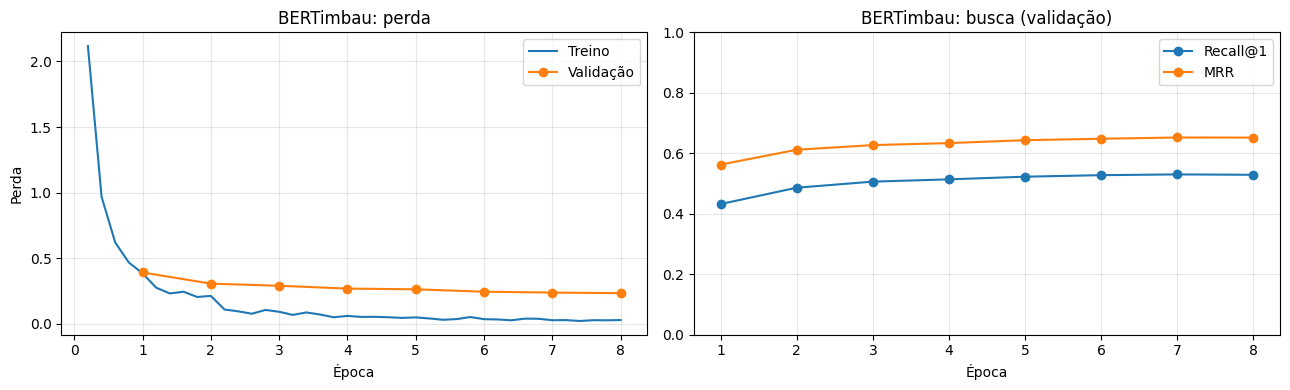

In [ ]:
if hist_bert:
    painel = ("busca_val", ["Recall@1", "MRR"], "busca") if hist_bert.get("busca_val") else None
    plotar_curvas(hist_bert, "BERTimbau", "curvas_bert.png", painel2=painel)

## 5. ChromaDB: guardar os vetores e buscar
Os vetores dos 2.017 artigos são calculados **uma vez** e ficam em disco (`models/chroma_db`). Na hora da pergunta só a pergunta vira vetor.

- `recuperar(pergunta, k)`: busca de **uma** pergunta pelo ChromaDB (usada no sistema interativo).
- `buscar_lote(perguntas, k)`: busca de **muitas** perguntas de uma vez, por produto de matrizes (usada nos treinos e avaliações, bem mais rápida). Dá o mesmo resultado; o código confere isso.

In [ ]:
import chromadb
from src.database.chroma_connection import ChromaConnection

# Garante persistência no diretório local do ChromaDB
CAMINHO_CHROMA.mkdir(parents=True, exist_ok=True)
cliente = chromadb.PersistentClient(path=str(CAMINHO_CHROMA))   # abre (ou cria) o banco no disco
try:
    colecao = cliente.get_collection(NOME_COLECAO)
except Exception:
    colecao = None

# Apaga a coleção se está desatualizada (BERT retreinado nesta execução ou número de artigos diferente).
if colecao is not None and (TREINAR_BERT or colecao.count() != len(passagens)):
    cliente.delete_collection(NOME_COLECAO)
    colecao = None

if colecao is None:
    vetores_passagens = modelo_bert.encode(textos_idx, normalize_embeddings=True, batch_size=64, show_progress_bar=True)
    colecao = cliente.create_collection(name=NOME_COLECAO, metadata={"hnsw:space": "cosine"})   # busca por cosseno
    for ini in range(0, len(passagens), 500):                    # envia em lotes de 500
        lote = passagens[ini:ini + 500]
        colecao.add(ids=[p["id"] for p in lote], embeddings=vetores_passagens[ini:ini + 500].tolist(),
                    documents=[p["texto"] for p in lote], metadatas=[{"citacao": p["citacao"]} for p in lote])
    print("Coleção criada com", colecao.count(), "vetores")
else:
    vetores_passagens = np.array(colecao.get(ids=ids_passagens, include=["embeddings"])["embeddings"])
    print("Coleção reaproveitada:", colecao.count(), "vetores")

def recuperar(pergunta, k=K_CONTEXTO):
    """Busca no ChromaDB. Devolve lista de (artigo, similaridade) do mais para o menos parecido."""
    vetor = modelo_bert.encode([pergunta], normalize_embeddings=True, show_progress_bar=False)
    r = colecao.query(query_embeddings=vetor.tolist(), n_results=k)
    return [({ "id": i, "citacao": m["citacao"], "texto": t}, 1.0 - d)
            for i, m, t, d in zip(r["ids"][0], r["metadatas"][0], r["documents"][0], r["distances"][0])]

def buscar_lote(perguntas, k=K_CONTEXTO):
    """Mesma busca, para várias perguntas de uma vez. Devolve, para cada pergunta, lista de (artigo, similaridade)."""
    vq = modelo_bert.encode(list(perguntas), normalize_embeddings=True, batch_size=64, show_progress_bar=False)
    sim = vq @ vetores_passagens.T
    topo = np.argsort(-sim, axis=1)[:, :k]
    return [[(passagens[j], float(sim[i, j])) for j in topo[i]] for i in range(len(perguntas))]

# Conferência: Chroma (aproximado) e produto de matrizes devem concordar no 1º colocado quase sempre.
amostra_conf = [l["pergunta"] for l in amostrar(busca_val, 20, SEED)]
igual = np.mean([recuperar(p, 1)[0][0]["id"] == b[0][0]["id"] for p, b in zip(amostra_conf, buscar_lote(amostra_conf, 1))])
print(f"Concordância Chroma × matriz no 1º artigo: {igual:.0%}")


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Coleção criada com 2017 vetores
Concordância Chroma × matriz no 1º artigo: 100%


## 6. Desempenho da busca (treino, validação e teste)
Para cada pergunta, vemos em que posição o artigo certo apareceu **entre os 2.017 artigos**:
- **Recall@k**: fração das perguntas em que o artigo certo está entre os `k` primeiros (Recall@1 = acerto direto).
- **MRR**: média de 1/posição (vale 1 se o certo é sempre o 1º).

| Conjunto | O que mede |
|---|---|
| treino (amostra) | o quanto o modelo aprendeu o que viu (só diagnóstico) |
| validação | artigos **novos**, usado para escolher época e limiar |
| teste visto | artigo conhecido, **pergunta nova** |
| teste novo | artigo **nunca visto**: a nota mais honesta |

In [ ]:
conjuntos_busca = {
    "treino (amostra)": amostrar(busca_treino, 800, SEED),
    "validação":        busca_val,
    "teste visto":      busca_teste_visto,
    "teste novo":       busca_teste_novo,
}
res_busca = {nome: metricas_busca(linhas, modelo_bert, vetores_passagens) for nome, linhas in conjuntos_busca.items()}

# BERTimbau ORIGINAL (sem ajuste) para mostrar quanto o fine-tuning ajudou. Só nos conjuntos de validação e teste.
res_busca_original = None
if AVALIAR_ORIGINAL:
    original = criar_encoder(MODELO_BASE)
    vet_original = original.encode(textos_idx, normalize_embeddings=True, batch_size=64, show_progress_bar=True)
    res_busca_original = {nome: metricas_busca(conjuntos_busca[nome], original, vet_original)
                          for nome in ["validação", "teste visto", "teste novo"]}
    del original

tabela = pd.DataFrame(res_busca).T
tabela.insert(0, "modelo", "BERTimbau ajustado")
if res_busca_original:
    t0_ = pd.DataFrame(res_busca_original).T
    t0_.insert(0, "modelo", "BERTimbau original")
    tabela = pd.concat([tabela, t0_])
print(tabela.round(3).to_string())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_1501/457438391.py:6: FutureWarning: The `get_word_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  media = models.Pooling(bert.get_word

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

                              modelo  Recall@1  Recall@3  Recall@5  Recall@10    MRR
treino (amostra)  BERTimbau ajustado     0.845     0.978     0.994      1.000  0.912
validação         BERTimbau ajustado     0.529     0.734     0.799      0.871  0.652
teste visto       BERTimbau ajustado     0.540     0.750     0.819      0.885  0.663
teste novo        BERTimbau ajustado     0.482     0.673     0.758      0.838  0.606
validação         BERTimbau original     0.181     0.278     0.324      0.413  0.258
teste visto       BERTimbau original     0.188     0.294     0.348      0.435  0.270
teste novo        BERTimbau original     0.149     0.250     0.295      0.364  0.226


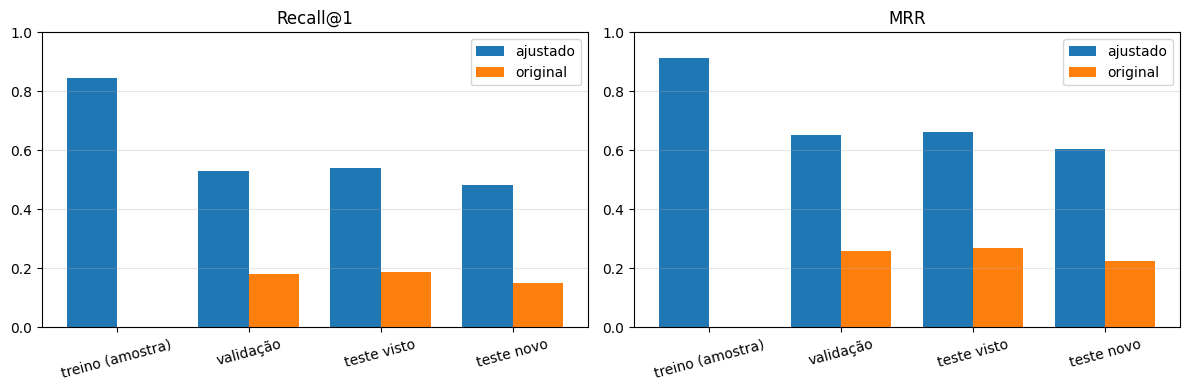

In [ ]:
# Gráfico de barras: Recall@1 e MRR por conjunto.
nomes = list(res_busca)
x = np.arange(len(nomes)); larg = 0.38
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for eixo, metrica in zip(eixos, ["Recall@1", "MRR"]):
    eixo.bar(x - larg / 2, [res_busca[n][metrica] for n in nomes], larg, label="ajustado")
    if res_busca_original:
        eixo.bar(x + larg / 2, [res_busca_original[n][metrica] if n in res_busca_original else 0 for n in nomes], larg, label="original")
    eixo.set_xticks(x); eixo.set_xticklabels(nomes, rotation=15); eixo.set_ylim(0, 1); eixo.set_title(metrica); eixo.grid(axis="y", alpha=0.3)
    eixo.legend()
fig.tight_layout(); fig.savefig(PASTA_RESULTADOS / "busca_transformer.png", dpi=150); plt.show()

## 7. Limiar de recusa
Se o artigo mais parecido tem **similaridade menor que o limiar**, o sistema recusa sem nem chamar o T5. O limiar é escolhido **na validação**, comparando a similaridade do melhor artigo para perguntas **dentro** do escopo (`busca_val`) e **fora** dele (perguntas de outras leis e assuntos gerais de `gerador_val`).

Regra: o **maior limiar que ainda aceita pelo menos 95%** das perguntas legítimas. Não precisa ser perfeito, porque o mt0 também aprende a recusar sozinho (parte 8); o limiar só barra os casos óbvios.

LIMIAR escolhido na validação = 0.465
  aceita 95% das perguntas do domínio | recusa 55% das perguntas de fora
  (dentro: média 0.64 | fora: média 0.44, n=22)


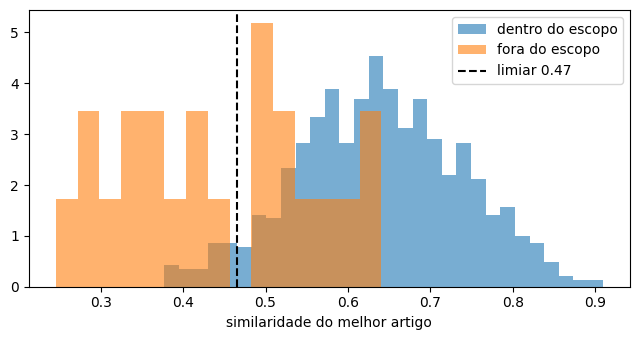

In [ ]:
sim_dentro = np.array([b[0][1] for b in buscar_lote([l["pergunta"] for l in busca_val], 1)])
fora_val   = [l["pergunta"] for l in gerador_val if l["artigo_id"] is None]
sim_fora   = np.array([b[0][1] for b in buscar_lote(fora_val, 1)])

candidatos = np.linspace(min(sim_dentro.min(), sim_fora.min()), max(sim_dentro.max(), sim_fora.max()), 300)
aceita_dentro = np.array([(sim_dentro >= c).mean() for c in candidatos])   # % das perguntas legítimas aceitas
recusa_fora   = np.array([(sim_fora < c).mean() for c in candidatos])      # % das perguntas de fora recusadas
validos = np.where(aceita_dentro >= 0.95)[0]                               # limiares que mantêm 95% das legítimas
LIMIAR = float(candidatos[validos[-1]]) if len(validos) else float(candidatos[0])
i = int(np.argmin(np.abs(candidatos - LIMIAR)))
print(f"LIMIAR escolhido na validação = {LIMIAR:.3f}")
print(f"  aceita {aceita_dentro[i]:.0%} das perguntas do domínio | recusa {recusa_fora[i]:.0%} das perguntas de fora")
print(f"  (dentro: média {sim_dentro.mean():.2f} | fora: média {sim_fora.mean():.2f}, n={len(sim_fora)})")

plt.figure(figsize=(6.5, 3.5))
plt.hist(sim_dentro, bins=30, alpha=0.6, label="dentro do escopo", density=True)
plt.hist(sim_fora, bins=15, alpha=0.6, label="fora do escopo", density=True)
plt.axvline(LIMIAR, color="k", ls="--", label=f"limiar {LIMIAR:.2f}")
plt.xlabel("similaridade do melhor artigo"); plt.legend(); plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "limiar_transformer.png", dpi=150); plt.show()

## 8. mt0 (T5): o modelo que escreve a resposta
O **mt0-base** é um T5 multilíngue. Ele recebe um **prompt** e escreve a resposta:

```
Explique em português simples... (instrução)

Dispositivos legais:
[Código Civil, art. 5º] A menoridade cessa aos dezoito anos...     <- os artigos que o BERT achou
[Código Civil, art. 4º] São incapazes...

Pergunta: Fiz 18 anos: posso fazer tudo sozinho?
Resposta:                                                           <- o T5 continua daqui
```

### O que entra no treino
Cada exemplo tem **entrada** = prompt (instrução + artigos que a busca achou + pergunta) e **alvo** = resposta simples + citação do artigo (`gerador_treino`). Para o modelo **não aprender atalhos**, a cada época o código:
1. **embaralha a posição** do artigo certo entre os artigos do prompt (senão ele aprenderia "a resposta está sempre no 1º");
2. em **10% dos exemplos remove o artigo certo** e troca o alvo pela frase de recusa (para aprender a recusar quando a busca falha);
3. inclui as perguntas **fora do escopo**, cujo alvo é sempre a recusa.

### Validação
Ao fim de cada época medimos a **perda** e a **acurácia de tokens** (quantos tokens do alvo o modelo acerta, recebendo o token anterior correto) em `gerador_val` (artigos novos), com a busca real (sem embaralhar nem remover nada). Ao final, o código **volta para a época de menor perda de validação**.

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

TREINAR_T5 = FORCAR_TREINO or not SAIDA_T5.exists()
print("Treinar mt0:", TREINAR_T5)
origem_t5 = NOME_T5 if TREINAR_T5 else str(SAIDA_T5)       # treina a partir do original; senão carrega o ajustado
tok = AutoTokenizer.from_pretrained(origem_t5)             # tokenizador: converte texto <-> números (tokens)
t5 = AutoModelForSeq2SeqLM.from_pretrained(origem_t5).to(DEVICE)   # o modelo em si
t5.eval()

INSTRUCAO = (
    "Explique em português simples, para quem não conhece direito, usando só os dispositivos legais abaixo. "
    "Não copie o texto da lei nem use palavras difíceis. Cite o artigo no final. "
    "Se os dispositivos não responderem à pergunta, diga que não há informação suficiente na base consultada."
)

def montar_prompt(pergunta, artigos):
    """Cola instrução + artigos + pergunta em um único texto (esta é a 'conexão' BERT -> T5)."""
    partes = [f"[{a['citacao']}] {a['texto'][:MAX_CHARS_TRECHO]}" for a in artigos]
    return INSTRUCAO + "\n\nDispositivos legais:\n" + "\n".join(partes) + f"\n\nPergunta: {pergunta}\nResposta:"

NUM_BEAMS = 1   # decodificação gulosa: escolhe a melhor palavra a cada passo (não favorece a frase de recusa)

def gerar_lote(prompts):
    """Faz o T5 escrever uma resposta para cada prompt (em grupos de BATCH_GERACAO)."""
    t5.eval(); t5.config.use_cache = True; respostas = []
    for i in range(0, len(prompts), BATCH_GERACAO):
        enc = tok(prompts[i:i + BATCH_GERACAO], return_tensors="pt", padding=True, truncation=True, max_length=MAX_ENTRADA).to(DEVICE)
        with torch.no_grad():
            saida = t5.generate(**enc, max_new_tokens=128, num_beams=NUM_BEAMS, no_repeat_ngram_size=3)
        respostas += tok.batch_decode(saida, skip_special_tokens=True)
    return respostas

def responder_lote(perguntas):
    """Sistema completo para várias perguntas: busca -> checa o limiar -> T5 escreve. Devolve um dict por pergunta."""
    buscas = buscar_lote(perguntas, K_CONTEXTO)
    saidas = [{"resposta": ABST, "artigos": [a for a, _ in b], "sim": b[0][1], "recusou_limiar": b[0][1] < LIMIAR} for b in buscas]
    pendentes = [i for i, s in enumerate(saidas) if not s["recusou_limiar"]]    # só chama o T5 se passou no limiar
    textos = gerar_lote([montar_prompt(perguntas[i], saidas[i]["artigos"]) for i in pendentes])
    for i, t in zip(pendentes, textos):
        saidas[i]["resposta"] = t
    return saidas

Treinar mt0: True


config.json:   0%|          | 0.00/798 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/430 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


In [ ]:
# Libera memória da GPU e usa lotes menores (o lote efetivo continua 16: 2 x 8)
import gc
for nome in ("trainer", "original", "otimizador", "enc", "rot", "perda"):
    globals().pop(nome, None)            # apaga objetos que ficaram na GPU
t5.zero_grad(set_to_none=True)           # descarta gradientes do passo que falhou
gc.collect(); torch.cuda.empty_cache()

BATCH_T5, ACUM_T5 = 2, 8                 # lote de 2, acumulando 8 passos
t5.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})  # troca um pouco de tempo por muita memória
t5.config.use_cache = False              # necessário com checkpointing durante o treino
print("GPU livre (GB):", round(torch.cuda.mem_get_info()[0] / 1e9, 1))

GPU livre (GB): 8.5


Tamanho dos prompts (tokens): máx 845 | média 410 | limite 1024


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


época 0 (mt0 original) | perda val 1.227 | acurácia tokens val 0.722
época 1/5 | perda treino 1.439 | perda val 1.162 | acurácia tokens val 0.736 | 458s  <- melhor
época 2/5 | perda treino 1.298 | perda val 1.133 | acurácia tokens val 0.744 | 912s  <- melhor
época 3/5 | perda treino 1.175 | perda val 1.109 | acurácia tokens val 0.749 | 1363s  <- melhor
época 4/5 | perda treino 1.083 | perda val 1.100 | acurácia tokens val 0.751 | 1816s  <- melhor
época 5/5 | perda treino 1.035 | perda val 1.099 | acurácia tokens val 0.752 | 2268s  <- melhor
Pesos restaurados da época 5 (menor perda de validação: 1.099)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

mt0 ajustado salvo em: /content/drive/MyDrive/JudAI/models/mt0-juridico


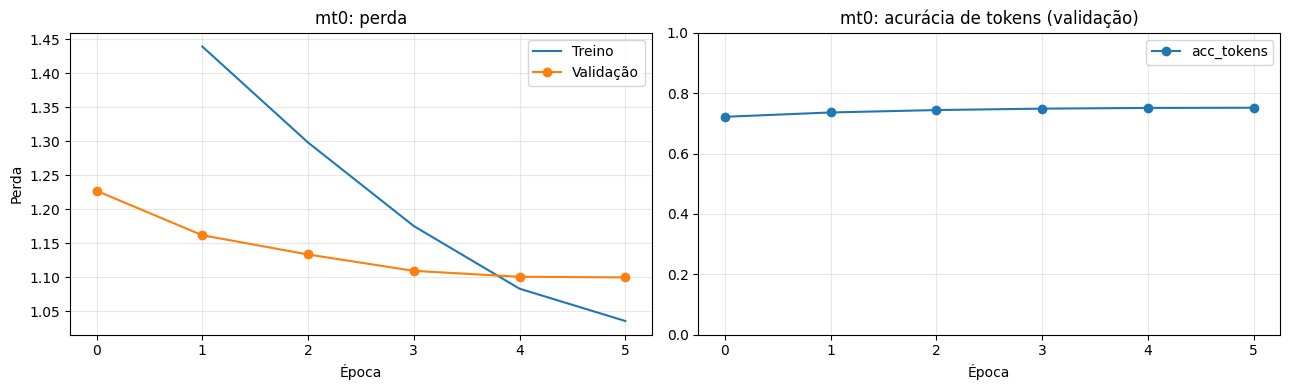

In [ ]:
ARQ_HIST_T5 = PASTA_RESULTADOS / "historico_t5.json"
hist_t5 = None

def contexto_do_exemplo(linha, achados, aleatorio):
    """
    Escolhe os artigos do prompt e o alvo de um exemplo. 'achados' = artigos da busca (do mais ao menos parecido).
    aleatorio=True  (TREINO): garante o artigo certo no prompt, embaralha a posição e às vezes o remove (alvo = recusa).
    aleatorio=False (VALIDAÇÃO): usa a busca como ela veio; se o artigo certo não veio, o alvo é recusa.
    """
    certo = linha["artigo_id"]
    if certo is None:                                         # pergunta fora do escopo: alvo é sempre a recusa
        return achados[:K_CONTEXTO], ABST
    outros = [a for a in achados if a["id"] != certo]
    if aleatorio:
        if random.random() < P_SEM_ARTIGO_CERTO:              # simula falha da busca
            return outros[:K_CONTEXTO], ABST
        ctx = outros[:K_CONTEXTO - 1] + [passagem_por_id[certo]]
        random.shuffle(ctx)                                   # o artigo certo nem sempre é o primeiro
        return ctx, linha["resposta"]
    if certo in [a["id"] for a in achados[:K_CONTEXTO]]:
        return achados[:K_CONTEXTO], linha["resposta"]
    return achados[:K_CONTEXTO], ABST

def preparar_lote(entradas, alvos):
    """Converte textos em tensores. Nos alvos, o preenchimento vira -100 (o modelo ignora esses pontos na perda)."""
    enc = tok(entradas, return_tensors="pt", padding=True, truncation=True, max_length=MAX_ENTRADA).to(DEVICE)
    rotulos = tok(text_target=alvos, return_tensors="pt", padding=True, truncation=True, max_length=200).input_ids.to(DEVICE)
    rotulos[rotulos == tok.pad_token_id] = -100
    return enc, rotulos

@torch.no_grad()
def avaliar_val(entradas, alvos):
    """Perda e acurácia de tokens (a cada token, o modelo recebe o anterior CORRETO e tenta prever o próximo)."""
    t5.eval()
    soma, acertos, total = 0.0, 0, 0
    for i in range(0, len(entradas), BATCH_T5):
        enc, rot = preparar_lote(entradas[i:i + BATCH_T5], alvos[i:i + BATCH_T5])
        saida = t5(**enc, labels=rot)
        valido = rot != -100                                   # só conta tokens de verdade, não o preenchimento
        n = int(valido.sum())
        soma += saida.loss.item() * n
        acertos += int(((saida.logits.argmax(-1) == rot) & valido).sum())
        total += n
    return soma / total, acertos / total

if TREINAR_T5:
    lin_treino = amostrar(gerador_treino, N_TREINO_T5, SEED)
    lin_val    = amostrar(gerador_val, N_VAL_T5, SEED)
    # Busca real para cada pergunta (uma vez só): serve para montar contexto de treino e de validação.
    ach_treino = [[a for a, _ in b] for b in buscar_lote([l["pergunta"] for l in lin_treino], K_CONTEXTO)]
    ach_val    = [[a for a, _ in b] for b in buscar_lote([l["pergunta"] for l in lin_val], K_CONTEXTO)]
    ent_val, alvo_val = [], []
    for l, ach in zip(lin_val, ach_val):
        ctx, alvo = contexto_do_exemplo(l, ach, aleatorio=False)
        ent_val.append(montar_prompt(l["pergunta"], ctx)); alvo_val.append(alvo)

    # Confere se algum prompt estoura MAX_ENTRADA (a pergunta fica no fim e seria cortada).
    comp = [len(tok(montar_prompt(l["pergunta"], ach[:K_CONTEXTO])).input_ids) for l, ach in zip(lin_treino[:300], ach_treino[:300])]
    print(f"Tamanho dos prompts (tokens): máx {max(comp)} | média {np.mean(comp):.0f} | limite {MAX_ENTRADA}")
    if max(comp) > MAX_ENTRADA:
        print("AVISO: há prompts maiores que o limite; reduza MAX_CHARS_TRECHO ou K_CONTEXTO.")

    # Congela as camadas de vocabulário (embeddings): economiza memória e tempo.
    for nome, parametro in t5.named_parameters():
        parametro.requires_grad = not nome.startswith(("shared", "lm_head"))
    treinaveis = [p for p in t5.parameters() if p.requires_grad]

    random.seed(SEED); torch.manual_seed(SEED)                # resultados repetíveis
    otimizador = torch.optim.AdamW(treinaveis, lr=LR_T5, weight_decay=0.01)    # quem ajusta os pesos
    lotes_por_epoca = math.ceil(len(lin_treino) / BATCH_T5)
    passos_total = math.ceil(lotes_por_epoca / ACUM_T5) * EPOCAS_T5
    agendador = get_linear_schedule_with_warmup(otimizador, max(1, passos_total // 10), passos_total)  # taxa sobe no início e desce até o fim

    hist_t5 = {"treino": [], "val": []}
    pv, av = avaliar_val(ent_val, alvo_val)                   # época 0 = antes de treinar
    hist_t5["val"].append({"epoca": 0, "perda": pv, "acc_tokens": av})
    print(f"época 0 (mt0 original) | perda val {pv:.3f} | acurácia tokens val {av:.3f}")

    melhor_perda, melhor_epoca, melhores_pesos = float("inf"), 0, None
    t0 = time.time()
    for epoca in range(1, EPOCAS_T5 + 1):
        # Monta os exemplos DESTA época (nova posição dos artigos, novo sorteio de "sem artigo certo").
        ent, alvos = [], []
        for l, ach in zip(lin_treino, ach_treino):
            ctx, alvo = contexto_do_exemplo(l, ach, aleatorio=True)
            ent.append(montar_prompt(l["pergunta"], ctx)); alvos.append(alvo)
        ordem = list(range(len(ent))); random.shuffle(ordem)   # embaralha a ordem dos exemplos
        t5.train()                                             # liga o modo de treino
        soma, total = 0.0, 0
        for b, i in enumerate(range(0, len(ordem), BATCH_T5)):
            idx = ordem[i:i + BATCH_T5]
            enc, rot = preparar_lote([ent[j] for j in idx], [alvos[j] for j in idx])
            perda = t5(**enc, labels=rot).loss                 # 1) o modelo tenta escrever o alvo e mede o erro
            (perda / ACUM_T5).backward()                       # 2) calcula como cada peso deveria mudar (acumulando ACUM_T5 lotes)
            if (b + 1) % ACUM_T5 == 0 or i + BATCH_T5 >= len(ordem):
                torch.nn.utils.clip_grad_norm_(treinaveis, 1.0)   # limita ajustes grandes demais (estabilidade)
                otimizador.step()                              # 3) ajusta os pesos
                agendador.step()                               #    atualiza a taxa de aprendizado
                otimizador.zero_grad()                         #    zera os cálculos para o próximo passo
            n = int((rot != -100).sum())
            soma += perda.item() * n; total += n
        pv, av = avaliar_val(ent_val, alvo_val)
        hist_t5["treino"].append({"epoca": epoca, "perda": soma / total})
        hist_t5["val"].append({"epoca": epoca, "perda": pv, "acc_tokens": av})
        marca = ""
        if pv < melhor_perda:                                  # guarda os pesos da melhor época
            melhor_perda, melhor_epoca = pv, epoca
            melhores_pesos = {n_: p.detach().cpu().clone() for n_, p in t5.named_parameters() if p.requires_grad}
            marca = "  <- melhor"
        print(f"época {epoca}/{EPOCAS_T5} | perda treino {soma/total:.3f} | perda val {pv:.3f} | "
              f"acurácia tokens val {av:.3f} | {time.time()-t0:.0f}s{marca}")

    with torch.no_grad():                                      # volta para a melhor época
        for n_, p in t5.named_parameters():
            if n_ in melhores_pesos:
                p.copy_(melhores_pesos[n_].to(p.device))
    t5.eval()
    print(f"Pesos restaurados da época {melhor_epoca} (menor perda de validação: {melhor_perda:.3f})")
    ARQ_HIST_T5.write_text(json.dumps(hist_t5, indent=1), encoding="utf-8")
    t5.save_pretrained(str(SAIDA_T5)); tok.save_pretrained(str(SAIDA_T5))   # salva modelo e tokenizador
    print("mt0 ajustado salvo em:", SAIDA_T5)
elif ARQ_HIST_T5.exists():
    hist_t5 = json.loads(ARQ_HIST_T5.read_text(encoding="utf-8"))

if hist_t5:
    plotar_curvas(hist_t5, "mt0", "curvas_t5.png", painel2=("val", ["acc_tokens"], "acurácia de tokens"))

## 9. Desempenho do sistema completo (busca + geração)
Cada pergunta passa pelo sistema inteiro (BERT → limiar → mt0). Métricas (definições na célula de código):

| Métrica | Leitura |
|---|---|
| `busca_ok` | o artigo certo estava entre as fontes dadas ao T5? (teto do que o T5 consegue acertar) |
| `resposta_com_artigo_certo` | **fim a fim**: % das perguntas que receberam uma resposta citando o artigo certo |
| `recusa_indevida` | recusou uma pergunta que tinha resposta (menor = melhor) |
| `recusa_correta_fora` | recusou pergunta fora do escopo (maior = melhor) |
| `rougeL` | semelhança com a resposta de referência |
| `copia_4gramas`, `palavras_longas` | quanto copia a lei e quanto usa palavras difíceis (menor = mais simples) |
| `numero_inventado` | resposta tem número que não está nas fontes (alucinação; menor = melhor) |

> Gerar texto é lento, então cada conjunto usa até `N_AVAL_GER` perguntas sorteadas. Para avaliar tudo, ponha `N_AVAL_GER = None`.

In [ ]:
conjuntos_ger = {
    "treino (amostra)": gerador_treino,
    "validação":        gerador_val,
    "teste visto":      gerador_teste_visto,
    "teste novo":       gerador_teste,
}
res_ger, previsoes = {}, []
t0 = time.time()
for nome, linhas in conjuntos_ger.items():
    m, prev = avaliar_geracao(linhas, responder_lote, n=N_AVAL_GER)
    res_ger[nome] = m
    previsoes += [{"conjunto": nome, **p} for p in prev]
    print(f"{nome:<18} ok ({m['n_dominio']} do domínio + {m['n_fora']} fora) | {time.time()-t0:.0f}s")

quadro = pd.DataFrame(res_ger).T
print(quadro.drop(columns=["n_dominio", "n_fora"]).round(3).to_string())

# Salva todas as respostas geradas, para a leitura manual do grupo (a avaliação humana é a mais importante).
with open(PASTA_RESULTADOS / "predicoes_transformer.jsonl", "w", encoding="utf-8") as f:
    for p in previsoes:
        f.write(json.dumps(p, ensure_ascii=False) + "\n")

treino (amostra)   ok (141 do domínio + 9 fora) | 35s
validação          ok (135 do domínio + 15 fora) | 73s
teste visto        ok (150 do domínio + 0 fora) | 108s
teste novo         ok (114 do domínio + 36 fora) | 139s
                  busca_ok  recusa_indevida  resposta_com_artigo_certo  rougeL  cita_artigo_certo  copia_4gramas  palavras_longas  palavras_por_frase  numero_inventado  recusa_correta_fora
treino (amostra)     0.972            0.099                      0.830   0.443              0.921          0.322            0.091              15.424             0.055                1.000
validação            0.852            0.104                      0.637   0.331              0.711          0.308            0.087              15.848             0.050                0.933
teste visto          0.760            0.347                      0.367   0.332              0.561          0.210            0.081              14.542             0.031                  NaN
teste novo           0.7

In [ ]:
# Exemplos lidos a olho: 6 respostas do TESTE NOVO (artigos que o modelo nunca viu no treino).
for p in [p for p in previsoes if p["conjunto"] == "teste novo"][:6]:
    print("P:", p["pergunta"])
    print("  Esperado:", p["referencia"])
    print("  Gerado:  ", p["resposta"])
    print("  Fontes:  ", p["fontes"], "| certo:", p["artigo_certo"], "\n")

P: Posso abrir mão do prazo de prescrição de uma dívida antes de ele acabar?
  Esperado: Não. Só é possível renunciar depois que o prazo já se completou, e isso não pode prejudicar terceiros. A renúncia pode ser dita expressamente ou deduzida de atitudes que não combinam com o uso da prescrição. (Código Civil, art. 191)
  Gerado:   Não. A renúncia à decadência fixada em lei não vale. (Código Civil, art. 209)
  Fontes:   ['Código Civil, art. 207', 'Código Civil, art. 199', 'Código Civil, art. 209'] | certo: cc2002:art191 

P: Qual o prazo para pedir a anulação de um contrato?
  Esperado: Quatro anos. Na coação conta do fim da ameaça; no erro, dolo, fraude contra credores, estado de perigo ou lesão, do dia do negócio; nos atos de incapazes, de quando a incapacidade acabar. (Código Civil, art. 178)
  Gerado:   É de quatro anos, contados da data da celebração. O prazo conta com o menor do dia em que o negócio é realizado. (Código Civil, art. 178)
  Fontes:   ['Código Civil, art. 178', 'Cód

## 10. Resumo salvo e testes manuais
O quadro final é salvo em `data/resultados/resultados_transformer.json` no **mesmo formato** do notebook do modelo clássico, para o notebook de comparação.

In [ ]:
resultados = {
    "modelo": "BERTimbau + mt0 (transformer)",
    "perfil": PERFIL,
    "limiar": LIMIAR,
    "config": {"epocas_bert": EPOCAS_BERT, "batch_bert": BATCH_BERT, "max_seq": MAX_SEQ, "epocas_t5": EPOCAS_T5,
               "k_contexto": K_CONTEXTO, "n_aval_ger": N_AVAL_GER, "pares_bert": N_PARES_BERT, "treino_t5": N_TREINO_T5},
    "busca": res_busca,
    "busca_original": res_busca_original,
    "geracao": res_ger,
}
(PASTA_RESULTADOS / "resultados_transformer.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=1), encoding="utf-8")
print("Salvo em", PASTA_RESULTADOS / "resultados_transformer.json")

Salvo em /content/drive/MyDrive/JudAI/data/resultados/resultados_transformer.json


In [ ]:
def mostrar(pergunta):
    """Sistema completo para uma pergunta, mostrando as fontes e a similaridade de cada uma."""
    saida = responder_lote([pergunta])[0]
    print("PERGUNTA:", pergunta)
    print("RESPOSTA:", saida["resposta"])
    print("FONTES:  ", [(a["citacao"], round(s, 3)) for (a, s) in buscar_lote([pergunta], K_CONTEXTO)[0]])
    print("-" * 80)

for p in ["A partir de que idade uma pessoa é considerada capaz?",
          "Meu vizinho construiu um muro na minha divisa. O que eu posso fazer?",
          "O que é união estável?",
          "Com qual idade posso me casar?",
          "Qual é a capital da França?"]:
    mostrar(p)

PERGUNTA: A partir de que idade uma pessoa é considerada capaz?
RESPOSTA: Aos dezoito anos completos. A pessoa fica habilitada à prática de todos os atos da vida civil. (Código Civil, art. 5o)
FONTES:   [('Código Civil, art. 4º', 0.729), ('Código Civil, art. 3º', 0.704), ('Código Civil, art. 5º', 0.67)]
--------------------------------------------------------------------------------
PERGUNTA: Meu vizinho construiu um muro na minha divisa. O que eu posso fazer?
RESPOSTA: Não encontrei informação suficiente no Código Civil para responder a essa pergunta.
FONTES:   [('Código Civil, art. 1.304', 0.628), ('Código Civil, art. 1.283', 0.627), ('Código Civil, art. 1.312', 0.622)]
--------------------------------------------------------------------------------
PERGUNTA: O que é união estável?
RESPOSTA: É a convivência pública, contínua e duradoura e estabelecida com o objetivo de constituir família. (Código Civil, art. 1.723)
FONTES:   [('Código Civil, art. 1.723', 0.804), ('Código Civil, art. 

In [ ]:
mostrar("Posso roubar?")

PERGUNTA: Posso cometer crimes?
RESPOSTA: Não. Quem, por ação ou omissão voluntária, violar direito e causar dano a outra pessoa, ainda que só moral, comete ato ilícito. (Código Civil, art. 186)
FONTES:   [('Código Civil, art. 186', 0.618), ('Código Civil, art. 188', 0.611), ('Código Civil, art. 1.600', 0.505)]
--------------------------------------------------------------------------------


In [ ]:
# DIAGNÓSTICO: o mt0 recusa por quê?
amostra = [l for l in amostrar(gerador_val, None) if l["artigo_id"]][:40]
buscas = buscar_lote([l["pergunta"] for l in amostra], K_CONTEXTO)
prompts = [montar_prompt(l["pergunta"], [a for a, _ in b]) for l, b in zip(amostra, buscas)]
com_certo = [l["artigo_id"] in [a["id"] for a, _ in b] for l, b in zip(amostra, buscas)]
sims = [b[0][1] for b in buscas]
print(f"LIMIAR={LIMIAR:.3f} | similaridade do 1º artigo: mín {min(sims):.2f}, média {np.mean(sims):.2f}")
print("barradas pelo limiar:", sum(s < LIMIAR for s in sims), "de", len(sims))

t5.eval(); t5.config.use_cache = True
def gerar_cfg(prompts, **kw):
    out = []
    for i in range(0, len(prompts), 8):
        enc = tok(prompts[i:i+8], return_tensors="pt", padding=True, truncation=True, max_length=MAX_ENTRADA).to(DEVICE)
        with torch.no_grad():
            o = t5.generate(**enc, max_new_tokens=128, no_repeat_ngram_size=3, **kw)
        out += tok.batch_decode(o, skip_special_tokens=True)
    return out
for nome, kw in [("beam 4 (atual)", dict(num_beams=4)), ("guloso (beam 1)", dict(num_beams=1))]:
    saidas = gerar_cfg(prompts, **kw)
    n_rec = sum(eh_abstencao(s) for s in saidas)
    print(f"{nome}: recusou {n_rec} de {len(saidas)}")
print("\nExemplo guloso:", saidas[0])

LIMIAR=0.465 | similaridade do 1º artigo: mín 0.51, média 0.69
barradas pelo limiar: 0 de 40
beam 4 (atual): recusou 24 de 40
guloso (beam 1): recusou 5 de 40

Exemplo guloso: Sim. As leis de lei não revogadas por este código ainda valem para empresários e sociedades empresárias, a não ser que o código revogue. (Código Civil, art. 2.037)
